# Why γ_eff ≠ GAMMA in cells with one plant type

Open item from 2026-10-30 (`analysis/MEGAN_ATTRIBUTION.md`, `src/boreal_forest_expansion/plotting/megan_maps.py`): in CTRL_PD JJA, cells where one PFT covers more than 90 % gave **γ_eff / GAMMA = 0.90–1.14**, where we expected 1.

**The two activities** (grid cell, monthly h0):

| Name | Definition | Weighting |
|---|---|---|
| γ_eff | `MEG / (k · EPS · f_valid)`, k = 1e-9/3600 | emission-weighted, exact by construction: E = k·f·ε·γ_eff |
| GAMMA | CLM field: γL·γT·γP·γA(·γC) per patch and step, then area mean | area-weighted |

With exactly one patch, γ_eff = mean(E)/(k ε) = mean(γ) = GAMMA, since ε is constant in time.

**Causes tested.**
1. The other patches: "one PFT > 90 %" still leaves up to 10 % of other patches with a different ε.
2. `f_valid`: built from `PCT_LANDUNIT`/`PCT_NAT_PFT` as natveg·(1 − bare) + crop + **lake**. Is that the area CLM averages EPS over?
3. Cutoff: CLM stores γ only if 0 ≤ γ < 100 (`VOCEmissionMod.F90`). Steps outside drop out of GAMMA but count in MEG.
4. Monoterpenes: GAMMA of the group = EPS-weighted mean over the 7 compounds with output.

**Data.** The patch-level tape (CLM h1, every patch, every 30-min step) of the 5-day CTRL_PD branch `NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-test-meganpatch-5day-20261029` (old chain, 2005-01-01 to 01-05, 240 steps; `megan_patch_branch_5day_test.ipynb`). The grid-cell values are rebuilt from it the way CLM averages patches (`subgridAveMod` p2g: weights `pfts1d_wtgcell`, patches with missing values left out at each step, then the time mean over the steps where the cell has a value). §2 checks the rebuild against the parent's real h0 (`NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023`, Jan 2005).

**Limit.** 5 days of **January**, not JJA: many boreal deciduous patches are leafless, so the weighting effect (cause 1) is larger here than in summer. The code of the original 0.90–1.14 check was not saved, so its definition of "one PFT > 90 %" is unknown; §4 tests several.

Outputs: `gamma_eff_vs_GAMMA_check_outputs/`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings('ignore', category=RuntimeWarning)

ARCHIVE = Path('/cluster/work/users/adelez/archive')
PARENT = 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023'
CASE = 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-test-meganpatch-5day-20261029'
GROUPS = {'isoprene': ['isoprene'],
          'MTERP': ['pinene_a', 'carene_3', 'pinene_b', 'myrcene', 'limonene', 'ocimene_t_b', 'sabinene']}
K = 1e-9 / 3600                       # kg s-1 per ug h-1 (megan_maps.K_UNITS)
LTYPE = {1: 'natural veg', 2: 'crop', 4: 'glacier', 5: 'lake', 6: 'wetland', 7: 'urban TBD', 8: 'urban HD', 9: 'urban MD'}
OUT = Path('gamma_eff_vs_GAMMA_check_outputs'); OUT.mkdir(exist_ok=True)

files = sorted((ARCHIVE / CASE / 'lnd/hist').glob('*.clm2.h1.*.nc'))
H0 = ARCHIVE / PARENT / 'lnd/hist' / f'{PARENT}.clm2.h0.2005-01.nc'
ds0 = xr.open_dataset(files[0], decode_times=False)
w = ds0.pfts1d_wtgcell.values; wl = ds0.pfts1d_wtlunit.values
lu = ds0.pfts1d_itype_lunit.values; veg = ds0.pfts1d_itype_veg.values
NLAT, NLON = ds0.sizes['lat'], ds0.sizes['lon']
cell = (ds0.pfts1d_jxy.values - 1) * NLON + (ds0.pfts1d_ixy.values - 1)
ucell, cid = np.unique(cell, return_inverse=True); NC = len(ucell)
clat = ds0.lat.values[ucell // NLON]

def gsum(x):
    """Sum over the patches of each grid cell."""
    return np.bincount(cid, weights=x, minlength=NC)

def load(v):
    return np.concatenate([xr.open_dataset(f, decode_times=False)[v].values for f in files]).astype(np.float64)

def to_map(x):
    m = np.full(NLAT * NLON, np.nan); m[ucell] = x
    return m.reshape(NLAT, NLON)

print(f'{len(files)} files, {load("mcsec").size} time steps, {len(w)} patches, {NC} land cells')

5 files, 240 time steps, 65485 patches, 5701 land cells


## §1 Which patches carry ε and γ

Per landunit type: patches whose EPS is missing (constant in time), whose GAMMA is missing in at least one step although EPS exists (cutoff), and whose MEG is missing. The docstring of `megan_maps.py` says EPS/GAMMA are 0 on lake.

In [2]:
eps_iso = ds0.EPS_isoprene.isel(time=0).values
G_iso = load('GAMMA_isoprene'); E_iso = load('MEG_isoprene')
rows = []
for L, name in LTYPE.items():
    m = lu == L
    rows.append({'landunit': name, 'patches': m.sum(),
                 'EPS missing': np.isnan(eps_iso[m]).sum(),
                 'of which bare (PFT 0)': (np.isnan(eps_iso) & m & (veg == 0)).sum(),
                 'GAMMA missing ≥1 step, EPS set': (~np.isfinite(G_iso[:, m]) & ~np.isnan(eps_iso[m])).any(0).sum(),
                 'MEG missing': np.isnan(E_iso[:, m]).any(0).sum()})
s1 = pd.DataFrame(rows); s1.to_csv(OUT / 's1_valid_patches.csv', index=False); s1

,landunit,patches,EPS missing,of which bare (PFT 0),"GAMMA missing ≥1 step, EPS set",MEG missing
0,natural veg,23966,4715,4715,74,0
1,crop,18857,0,0,1519,0
2,glacier,6638,6638,6638,0,0
3,lake,1472,1472,1472,0,0
4,wetland,27,27,27,0,0
5,urban TBD,550,550,550,0,0
6,urban HD,6745,6745,6745,0,0
7,urban MD,7230,7230,7230,0,0


## §2 Rebuild CLM's grid-cell values, and check it against the real h0

Per compound, from the patch tape:
- **MEG**: every patch, cell weights sum to 1 (lake/urban/bare emit 0).
- **EPS**: mean over the patches where EPS exists, weighted by `wtgcell`; the area they cover is `f_true`.
- **GAMMA**: at each step the weighted mean over the patches where GAMMA exists, then the mean over steps (CLM skips steps where a cell has no value).
- `GAMMA_cut0`: as GAMMA, but cutoff steps counted as γ = 0 (used in §5).

Groups as in `megan_maps.load_factors`: E and EPS summed over compounds, GAMMA = EPS-weighted mean of the compound GAMMAs.

`f_ours` = the `megan_maps.py` formula natveg·(1 − bare share) + crop + lake, written with the patch weights (same surface data).

The h0 check uses EPS, which is constant in time, so 5 days and the monthly h0 must agree exactly.

In [3]:
def compound_terms(c):
    E = load(f'MEG_{c}'); G = load(f'GAMMA_{c}'); eps = ds0[f'EPS_{c}'].isel(time=0).values.astype(np.float64)
    val = ~np.isnan(eps); fin = np.isfinite(G)
    f_true = gsum(np.where(val, w, 0.))
    num = np.stack([gsum(np.where(fin[t], G[t] * w, 0.)) for t in range(len(G))])
    den = np.stack([gsum(np.where(fin[t], w, 0.)) for t in range(len(G))])
    ok = val[None, :] & fin & (E > 0)
    r = E[ok] / (K * np.broadcast_to(eps, E.shape)[ok] * G[ok])
    return {'meg': gsum(E.mean(0) * w), 'eps': gsum(np.where(val, eps * w, 0.)) / f_true,
            'gamma': np.nanmean(np.where(den > 0, num / np.where(den > 0, den, 1.), np.nan), 0),
            'gamma_cut0': gsum(np.where(val, np.nan_to_num(G, nan=0.).mean(0) * w, 0.)) / f_true,
            'f_true': f_true, 'val': val, 'Ew': E.mean(0) * w,
            'cut': (val[None, :] & ~fin).sum(0), 'E_at_cut': np.abs(E[val[None, :] & ~fin]).max(initial=0.),
            'patch_ratio': (r.min(), r.max()), 'eps_patch': eps}

T = {c: compound_terms(c) for cs in GROUPS.values() for c in cs}

natveg = gsum(np.where(lu == 1, w, 0.)); crop = gsum(np.where(lu == 2, w, 0.))
lake = gsum(np.where(lu == 5, w, 0.)); bare = gsum(np.where((lu == 1) & (veg == 0), w, 0.))
f_ours = (natveg - bare) + crop + lake
f_true = T['isoprene']['f_true']; val = T['isoprene']['val']
assert all((T[c]['val'] == val).all() for c in T)

G = {}
for g, cs in GROUPS.items():
    meg = sum(T[c]['meg'] for c in cs); eps = sum(T[c]['eps'] for c in cs)
    G[g] = {'meg': meg, 'eps': eps,
            'GAMMA': sum(T[c]['eps'] * T[c]['gamma'] for c in cs) / eps,
            'GAMMA_cut0': sum(T[c]['eps'] * T[c]['gamma_cut0'] for c in cs) / eps,
            'Ew': sum(T[c]['Ew'] for c in cs)}
    G[g]['ge_true'] = meg / (K * eps * f_true)
    G[g]['ge_ours'] = meg / (K * eps * f_ours)
    G[g]['ok'] = (eps > 0) & (meg > 0) & (G[g]['GAMMA'] > 0)

h0 = xr.open_dataset(H0, decode_times=False)
rows = []
for c in ['isoprene', 'pinene_a']:
    eps = T[c]['eps_patch']
    H = h0[f'EPS_{c}'].isel(time=0).values.ravel()[ucell].astype(float)
    m = np.isfinite(H) & (H > 0) & (H < 1e30) & (f_true > 0)
    for name, x in [('valid patches only (f_true)', T[c]['eps']),
                    ('lake counted as EPS = 0', gsum(np.where(val, eps * w, 0.)) / gsum(np.where(val | (lu == 5), w, 0.)))]:
        d = np.abs(H[m] / x[m] - 1)
        rows.append({'compound': c, 'rebuild': name, 'cells': m.sum(), 'max |h0/rebuild − 1|': d.max(),
                     'max in lake cells (>1 %)': d[lake[m] > 0.01].max(), 'lake cells': (lake[m] > 0.01).sum()})
s2 = pd.DataFrame(rows); s2.to_csv(OUT / 's2_eps_rebuild_vs_h0.csv', index=False); s2

,compound,rebuild,cells,max |h0/rebuild − 1|,max in lake cells (>1 %),lake cells
0,isoprene,valid patches only (f_true),4089,4.130030e-14,4.085621e-14,1204
1,isoprene,lake counted as EPS = 0,4089,5.473516e+02,5.473516e+02,1204
2,pinene_a,valid patches only (f_true),4089,4.107825e-14,4.096723e-14,1204
3,pinene_a,lake counted as EPS = 0,4089,5.473516e+02,5.473516e+02,1204


## §3 Are the definitions right?

(i) Per patch and step, E = k·ε·GAMMA. (ii) In cells with **exactly one** valid patch, γ_eff / GAMMA must be 1.

In [4]:
nval = gsum(val.astype(float))
rows = [{'test': f'E / (k ε GAMMA) per patch-step, {c}', 'min': T[c]['patch_ratio'][0], 'max': T[c]['patch_ratio'][1]} for c in T]
for g in GROUPS:
    s = G[g]['ok'] & (nval == 1); r = G[g]['ge_true'][s] / G[g]['GAMMA'][s]
    rows.append({'test': f'γ_eff / GAMMA, cells with one valid patch (n={s.sum()}), {g}', 'min': r.min(), 'max': r.max()})
s3 = pd.DataFrame(rows); s3.to_csv(OUT / 's3_definitions.csv', index=False)
s3.style.format({'min': '{:.6f}', 'max': '{:.6f}'})

,test,min,max
0,"E / (k ε GAMMA) per patch-step, isoprene",1.000000,1.000000
1,"E / (k ε GAMMA) per patch-step, pinene_a",1.000000,1.000000
2,"E / (k ε GAMMA) per patch-step, carene_3",1.000000,1.000000
3,"E / (k ε GAMMA) per patch-step, pinene_b",1.000000,1.000000
4,"E / (k ε GAMMA) per patch-step, myrcene",1.000000,1.000000
5,"E / (k ε GAMMA) per patch-step, limonene",1.000000,1.000000
6,"E / (k ε GAMMA) per patch-step, ocimene_t_b",1.000000,1.000000
7,"E / (k ε GAMMA) per patch-step, sabinene",1.000000,1.000000
8,"γ_eff / GAMMA, cells with one valid patch (n=5), isoprene",1.000000,1.000000
9,"γ_eff / GAMMA, cells with one valid patch (n=5), MTERP",1.000000,1.000000


## §4 Cause 1: the other patches

γ_eff / GAMMA (with `f_true`, so cause 2 is excluded) for several definitions of "one plant type":
- **A**: one natural PFT > 90 % of the natural-vegetation landunit (`PCT_NAT_PFT` style, bare ground counted as a PFT), split by whether the dominant is bare and by crop share.
- **B / C**: one patch > 90 % / > 99 % of the valid area (natural veg + crop).
- B split by the share of the cell's emission that comes from the dominant patch.

In [5]:
sv = np.where(val, w, 0.) / f_true[cid]
sdom = np.zeros(NC); np.maximum.at(sdom, cid, sv)
order = np.lexsort((sv, cid)); last = np.r_[cid[order][1:] != cid[order][:-1], True]
pdom = np.full(NC, -1); pdom[cid[order][last]] = order[last]          # dominant valid patch of each cell
dnat = np.zeros(NC); np.maximum.at(dnat, cid, np.where(lu == 1, wl, 0.))
bare_dom = gsum(np.where((lu == 1) & (veg == 0), wl, 0.)) > 0.9

def stats(x):
    if len(x) == 0:
        return {'n': 0}
    p = np.percentile(x, [5, 50, 95])
    return {'n': len(x), 'min': x.min(), 'p5': p[0], 'median': p[1], 'p95': p[2], 'max': x.max(),
            '|r−1| > 0.1': int((np.abs(x - 1) > 0.1).sum())}

rows = []
for g in GROUPS:
    R = G[g]['ge_true'] / G[g]['GAMMA']; ok = G[g]['ok']
    edom = G[g]['Ew'][pdom] / G[g]['meg']
    G[g]['edom'] = edom
    for name, sel in [('A  natural PFT > 90 % of natveg landunit', dnat > 0.9),
                      ('A  … dominant = bare ground', (dnat > 0.9) & bare_dom),
                      ('A  … dominant vegetated, crop < 1 % of cell', (dnat > 0.9) & ~bare_dom & (crop < 0.01)),
                      ('A  … dominant vegetated, crop ≥ 1 % of cell', (dnat > 0.9) & ~bare_dom & (crop >= 0.01)),
                      ('B  one patch > 90 % of valid area', sdom > 0.9),
                      ('C  one patch > 99 % of valid area', sdom > 0.99),
                      ('B  … dominant gives > 90 % of the emission', (sdom > 0.9) & (edom > 0.9)),
                      ('B  … dominant gives < 50 % of the emission', (sdom > 0.9) & (edom < 0.5))]:
        rows.append({'group': g, 'cells': name, **stats(R[ok & sel])})
s4 = pd.DataFrame(rows); s4.to_csv(OUT / 's4_other_patches.csv', index=False)
s4.style.format({k: '{:.3f}' for k in ['min', 'p5', 'median', 'p95', 'max']}, na_rep='')

,group,cells,n,min,p5,median,p95,max,|r−1| > 0.1
0,isoprene,A natural PFT > 90 % of natveg landunit,333,0.139,0.307,1.007,11.263,93.716,180
1,isoprene,A … dominant = bare ground,130,0.139,0.221,1.019,17.036,93.716,102
2,isoprene,"A … dominant vegetated, crop < 1 % of cell",89,0.758,0.992,1.000,1.793,3.549,13
3,isoprene,"A … dominant vegetated, crop ≥ 1 % of cell",114,0.253,0.346,1.028,3.091,9.697,65
4,isoprene,B one patch > 90 % of valid area,257,0.234,0.721,1.000,3.349,11.543,122
5,isoprene,C one patch > 99 % of valid area,52,0.733,0.746,0.999,1.858,1.877,19
6,isoprene,B … dominant gives > 90 % of the emission,152,0.347,0.724,1.000,1.028,1.063,19
7,isoprene,B … dominant gives < 50 % of the emission,101,0.234,0.733,1.740,3.828,11.543,101
8,MTERP,A natural PFT > 90 % of natveg landunit,337,0.015,0.057,1.002,52.161,157.838,195
9,MTERP,A … dominant = bare ground,132,0.015,0.040,0.975,27.203,157.838,103


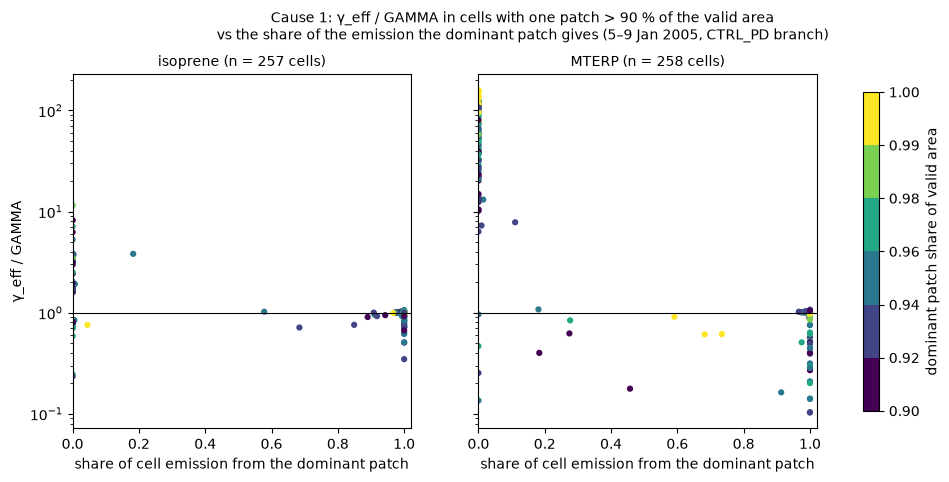

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
norm = mcolors.BoundaryNorm([0.9, 0.92, 0.94, 0.96, 0.98, 0.99, 1.0], 256)
for ax, g in zip(axes, GROUPS):
    s = G[g]['ok'] & (sdom > 0.9)
    sc = ax.scatter(G[g]['edom'][s], (G[g]['ge_true'] / G[g]['GAMMA'])[s], c=sdom[s], s=12, cmap='viridis', norm=norm)
    ax.axhline(1, color='k', lw=0.8); ax.set_yscale('log'); ax.set_xlim(0, 1.02)
    ax.set_xlabel('share of cell emission from the dominant patch')
    ax.set_title(f'{g} (n = {s.sum()} cells)', fontsize=10)
axes[0].set_ylabel('γ_eff / GAMMA')
cb = fig.colorbar(sc, ax=axes, shrink=0.9, ticks=[0.9, 0.92, 0.94, 0.96, 0.98, 0.99, 1.0])
cb.set_label('dominant patch share of valid area')
fig.suptitle('Cause 1: γ_eff / GAMMA in cells with one patch > 90 % of the valid area\nvs the share of the emission the dominant patch gives (5–9 Jan 2005, CTRL_PD branch)', fontsize=10, y=1.02)
fig.savefig(OUT / 's4_ratio_vs_dominant_emission.png', dpi=150, bbox_inches='tight')

## §5 Cause 2: lake in `f_valid`

§1–§2 show where EPS exists. Here: how much `f_ours` (with lake) overstates the valid area north of 45°N, and what it does to γ_eff / GAMMA. γ_eff is divided by f, so γ_eff_ours = γ_eff_true · f_true / f_ours.

In [7]:
fr = f_ours / f_true
n45 = (clat >= 45) & (f_true > 0)
rows = [{'quantity': 'f_ours / f_true, land cells ≥ 45°N', **stats(fr[n45])}]
for g in GROUPS:
    ok = G[g]['ok'] & (dnat > 0.9) & (lake > 0.01)
    rows.append({'quantity': f'γ_eff/GAMMA with f_ours, A cells with lake > 1 %, {g}', **stats((G[g]['ge_ours'] / G[g]['GAMMA'])[ok])})
    rows.append({'quantity': f'γ_eff/GAMMA with f_true, same cells, {g}', **stats((G[g]['ge_true'] / G[g]['GAMMA'])[ok])})
s5 = pd.DataFrame(rows); s5.to_csv(OUT / 's5_lake_in_f_valid.csv', index=False)
print(f'≥45°N land cells with f_ours/f_true > 1.05: {(fr[n45] > 1.05).sum()} of {n45.sum()}')
s5.style.format({k: '{:.3f}' for k in ['min', 'p5', 'median', 'p95', 'max']}, na_rep='')

≥45°N land cells with f_ours/f_true > 1.05: 394 of 1733


,quantity,n,min,p5,median,p95,max,|r−1| > 0.1
0,"f_ours / f_true, land cells ≥ 45°N",1733,1.000,1.000,1.000,1.205,6.271,219
1,"γ_eff/GAMMA with f_ours, A cells with lake > 1 %, isoprene",68,0.002,0.529,0.983,2.405,11.328,22
2,"γ_eff/GAMMA with f_true, same cells, isoprene",68,0.503,0.819,1.004,2.473,14.618,19
3,"γ_eff/GAMMA with f_ours, A cells with lake > 1 %, MTERP",68,0.002,0.208,0.988,56.642,72.177,23
4,"γ_eff/GAMMA with f_true, same cells, MTERP",68,0.158,0.621,1.006,57.805,75.245,23


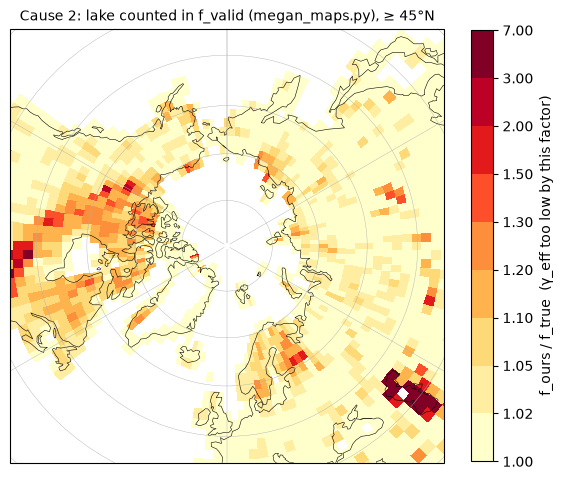

In [8]:
lon = ds0.lon.values; lat = ds0.lat.values
levels = [1.0, 1.02, 1.05, 1.1, 1.2, 1.3, 1.5, 2.0, 3.0, 7.0]
norm = mcolors.BoundaryNorm(levels, 256)
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 45, 90], ccrs.PlateCarree())
pm = ax.pcolormesh(lon, lat, to_map(np.where(f_true > 0, fr, np.nan)), transform=ccrs.PlateCarree(), cmap='YlOrRd', norm=norm)
ax.add_feature(cfeature.COASTLINE, lw=0.4); ax.gridlines(lw=0.3)
cb = fig.colorbar(pm, ax=ax, shrink=0.8, ticks=levels); cb.set_label('f_ours / f_true  (γ_eff too low by this factor)')
ax.set_title('Cause 2: lake counted in f_valid (megan_maps.py), ≥ 45°N', fontsize=10)
fig.savefig(OUT / 's5_f_ours_over_f_true_map.png', dpi=150, bbox_inches='tight')

## §6 Cause 3: the cutoff (γ outside [0, 100) not stored)

Patch-steps where EPS exists but GAMMA is missing, which PFTs they are in, the emission at those steps, and how much γ_eff / GAMMA changes if those steps are counted as γ = 0 (consistent with E = 0) instead of being left out.

In [9]:
rows = [{'compound': c, 'cutoff patch-steps': int(T[c]['cut'].sum()), 'patches': int((T[c]['cut'] > 0).sum()),
         'max |MEG| at cutoff steps': T[c]['E_at_cut']} for c in T]
s6a = pd.DataFrame(rows); s6a.to_csv(OUT / 's6a_cutoff_counts.csv', index=False); display(s6a)
cp = T['isoprene']['cut'] > 0
pft, n = np.unique(veg[cp], return_counts=True)
s6b = pd.DataFrame({'PFT/CFT (itype_veg)': pft, 'patches with cutoff (isoprene)': n}); s6b.to_csv(OUT / 's6b_cutoff_pfts.csv', index=False); display(s6b.T)
rows = []
for g in GROUPS:
    d = np.abs(G[g]['GAMMA'] / G[g]['GAMMA_cut0'] - 1); ok = G[g]['ok']
    for name, sel in [('all cells', ok), ('≥ 45°N', ok & (clat >= 45)), ('B cells (one patch > 90 %)', ok & (sdom > 0.9))]:
        rows.append({'group': g, 'cells': name, 'n': sel.sum(), 'change > 1 %': int((d[sel] > 0.01).sum()), 'max change': d[sel].max()})
s6c = pd.DataFrame(rows); s6c.to_csv(OUT / 's6c_cutoff_effect.csv', index=False); s6c

,compound,cutoff patch-steps,patches,max |MEG| at cutoff steps
0,isoprene,218885,1593,0.0
1,pinene_a,0,0,0.0
2,carene_3,0,0,0.0
3,pinene_b,0,0,0.0
4,myrcene,0,0,0.0
5,limonene,0,0,0.0
6,ocimene_t_b,0,0,0.0
7,sabinene,0,0,0.0


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
PFT/CFT (itype_veg),6,10,13,14,15,17,23,41,61,62,67,68,77,78
patches with cutoff (isoprene),14,7,24,29,9,1,9,24,516,327,387,231,9,6


,group,cells,n,change > 1 %,max change
0,isoprene,all cells,3188,334,5.863487e+00
1,isoprene,≥ 45°N,1040,1,1.406104e-02
2,isoprene,B cells (one patch > 90 %),257,4,2.645360e-02
3,MTERP,all cells,3205,0,1.776357e-15
4,MTERP,≥ 45°N,1040,0,1.776357e-15
5,MTERP,B cells (one patch > 90 %),258,0,1.554312e-15


## §7 Summary

Numbers from the tables above (5–9 Jan 2005, CTRL_PD old-chain branch); evidence tag **(a)** = shown by this notebook, **(b)** = inference.

| Cause | Verdict |
|---|---|
| Definitions | **Right (a).** E = k·ε·GAMMA per patch-step (ratio 1.000000); cells with exactly one valid patch give γ_eff / GAMMA = 1.000 for isoprene and MTERP (§3). |
| 1. Other patches | **Explains the mismatch (a).** Even with one patch > 99 % of the valid area the ratio spans 0.73–1.88 (isoprene) and 0.61–158 (MTERP); with > 90 % 0.23–11.5 (isoprene) in January (§4). Large deviations come from cells where the dominant patch gives little of the emission (leafless or low-ε dominant, small high-ε patch): of the B cells with \|r − 1\| > 0.1, 101 of 122 (isoprene) have the dominant giving < 50 % of the emission; where it gives > 90 %, the median is 1.000. This is the expected emission- vs area-weighting, i.e. the **weighting** term of the residual, not an error. The smaller summer range (0.90–1.14) fits a dominant forest that emits in JJA **(b)**. |
| 2. Lake in `f_valid` | **Bug in `megan_maps.load_factors` (a).** EPS/GAMMA are missing on lake patches (§1), and CLM's grid-cell EPS is the mean over vegetated + crop patches only: the rebuild matches h0 to ~1e-14, while counting lake as EPS = 0 is off by up to ~550× (§2). `f_valid` must be natveg·(1 − bare) + crop, **without lake**. North of 45°N 394 of 1733 land cells (≈ 1 in 4) have f_ours / f_true > 1.05, up to 6.3 (§5), so γ_eff is too low there by that factor. The total Δln E is not affected; the split of Δln E into composition (f·ε) and γ_eff, and the weighting panel, are, in cells with lake where the valid vegetated area changes between CTRL and LCC **(b)** (size not computed). The docstring "lake = 0" is wrong too. |
| 3. Cutoff | **Minor, and negligible north of 45°N (a).** Isoprene only (no MTERP cutoff steps): 218,885 patch-steps in 1593 patches, 1461 of them crop CFTs 61/62/67/68; MEG = 0 at all of them. Counting them as γ = 0 changes the ratio by > 1 % in 334 of 3188 cells globally, in 1 cell ≥ 45°N, and in 4 B cells (max 2.6 %) (§6). |
| 4. MTERP weighting | **No extra issue (a).** Same mechanism as cause 1, with a larger spread because MTERP ε differs more between plant types (likely case (b): a small needleleaf patch in a grass/crop cell); where the dominant patch gives > 90 % of the emission the ratio is 0.10–1.07, median 1.000 (§4). |

**Not affected:** the exact LMDI split of the production branch runs (`postprocess/megan_lmdi/`), which works per patch and step.

**Fix (not applied, needs the user's OK):** drop `+ pl.isel(ltype=4)` from `f_valid` in `megan_maps.load_factors`, correct the docstring, rerun `analysis/megan_factor_maps.ipynb`.